# Automated OTC Trade Reconciliation (EMIR-style)

Every day, a bank's operations team compares its own booking of each OTC derivative with
the counterparty's version. Under EMIR, both sides report every trade to a trade repository,
and the two reports must agree on the Unique Trade Identifier (UTI) and the key economic
fields. Any difference (a "break") must be investigated and fixed.

This notebook builds the reconciliation engine end to end:

1. Two books of 5,000 trades (ours and the counterparties'), with realistic breaks injected
2. Matching on UTI, then **economic matching** for trades whose UTI is missing
3. Field-by-field comparison with tolerances, classified by type and severity
4. A formatted Excel report for the operations team, and a scale test

Trades, identifiers and amounts are synthetic.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("recon.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/23-trade-reconciliation")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recon import generate_trades, counterparty_view, reconcile, summary, write_excel, Tolerances

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
internal = generate_trades(5_000, seed=0)
external, truth = counterparty_view(internal, break_rate=0.04, seed=1)
internal.head()

,uti,counterparty,product,trade_date,maturity,currency,notional,rate,direction,mtm
0,UTI0000000000,Barclays,FX forward,2026-09-14,2026-12-14,EUR,11300000.0,1.084737,Pay,-40152.61
1,UTI0000000001,Deutsche Bank,IRS,2026-07-12,2031-07-12,USD,26300000.0,0.028454,Pay,-229615.13
2,UTI0000000002,Goldman Sachs,CDS,2026-06-04,2029-06-03,USD,61700000.0,0.021832,Receive,1441639.18
3,UTI0000000003,BofA Securities,FX forward,2026-03-23,2026-09-21,EUR,20900000.0,1.096621,Receive,-516638.48
4,UTI0000000004,HSBC,FX forward,2026-04-04,2027-04-04,USD,32300000.0,1.055501,Pay,28546.35


## 1. What can go wrong

The counterparties' file differs from ours in the ways that happen in real life: trades
booked on one side only, a wrong notional, a fixed rate typed with an extra basis point, the
direction flipped (pay vs receive), a maturity one day off, the wrong currency, a valuation
gap, and trades reported without a UTI. Small valuation noise (a few hundred euros) is added
everywhere, and should **not** be flagged.

In [2]:
truth["break"].value_counts().to_frame("Injected")

,Injected
break,
missing at counterparty,25
notional,25
rate,25
direction,25
maturity,25
currency,25
mtm,25
uti missing,25
missing internally,25


## 2. Reconciliation

| Step | Rule |
|---|---|
| UTI match | exact key |
| Economic match | same counterparty, product, trade date and currency; closest notional (within 25%); one-to-one |
| Notional | relative difference above 0.01% |
| Rate | above 0.5 bp (or 1 pip of relative difference for FX forwards) |
| MTM | above max(EUR 5k, 2% of the MTM) |
| Dates, direction, currency | exact |

In [3]:
res = reconcile(internal, external, Tolerances())
breaks = res["breaks"]
summary(res, len(internal))

,Value
Internal trades,5000.00
Matched on UTI,4950.00
Matched on economics,25.00
Trades with a break,200.00
High-severity breaks,125.00
Run time (s),0.05


In [4]:
found = set(zip(breaks["uti"], breaks["field"]))
expected = set(zip(truth.loc[truth["break"] != "uti missing", "uti"], truth.loc[truth["break"] != "uti missing", "break"]))
print(f"Breaks injected: {len(expected)}   detected: {len(found & expected)}   false alarms: {len(found - expected)}")
print(f"Trades without UTI matched on economics: {(res['matched']['match_method'] == 'Economic').sum()} of {(truth['break'] == 'uti missing').sum()}")

Breaks injected: 200   detected: 200   false alarms: 0
Trades without UTI matched on economics: 25 of 25


Every injected break is found and correctly classified, with no false alarm: the valuation
noise stays inside the tolerance, and the trades without a UTI are paired on their economics
instead of showing up as two one-sided breaks.

## 3. Where are the breaks?

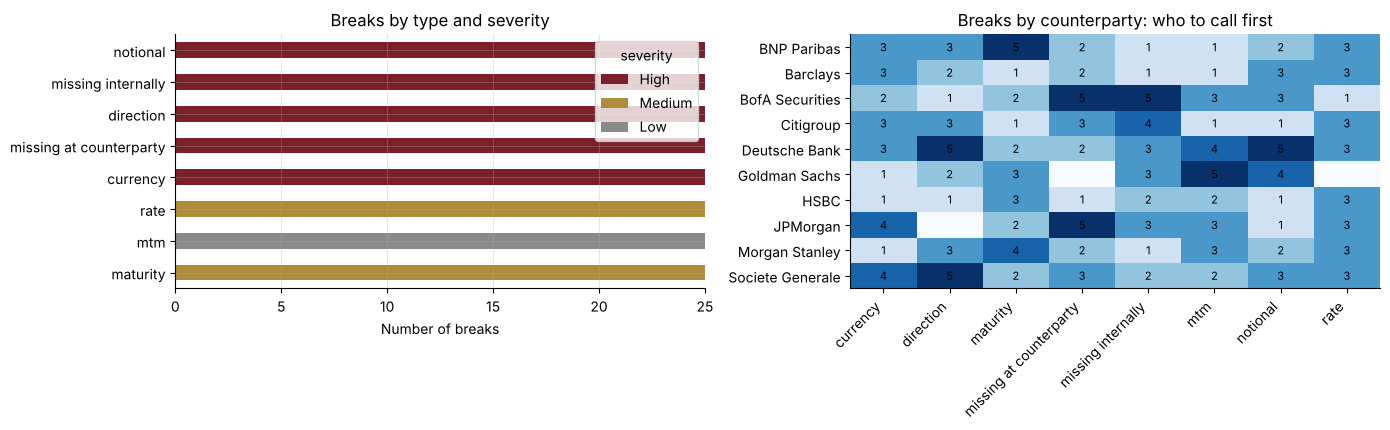

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
by_type = breaks.groupby(["field", "severity"]).size().unstack(fill_value=0).reindex(columns=["High", "Medium", "Low"], fill_value=0)
by_type.sort_values("High").plot.barh(stacked=True, color=[BORDEAUX, GOLD, GREY], ax=axes[0])
axes[0].set(xlabel="Number of breaks", ylabel="", title="Breaks by type and severity")
heat = breaks.pivot_table(index="counterparty", columns="field", values="uti", aggfunc="count", fill_value=0)
im = axes[1].imshow(heat.values, cmap="Blues", aspect="auto")
axes[1].set_xticks(range(heat.shape[1]), heat.columns, rotation=45, ha="right"); axes[1].set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if heat.values[i, j]:
            axes[1].text(j, i, heat.values[i, j], ha="center", va="center", fontsize=8)
axes[1].set_title("Breaks by counterparty: who to call first"); axes[1].grid(False)
plt.tight_layout(); plt.savefig("images/breaks.png", dpi=150); plt.show()

The severity follows what EMIR reporting cares about: a wrong notional, direction or
currency misstates the bank's exposure (High), a date or rate typo distorts the valuation
(Medium), a valuation gap within a collateral dispute window is Low.

## 4. The Excel report

Operations teams live in Excel, so the output is a workbook: a summary, a counterparty ×
break-type table, and the full list of breaks with filters and colour-coded severity.

In [6]:
write_excel(res, len(internal), "reconciliation_report.xlsx")
print({k: v.shape for k, v in pd.read_excel("reconciliation_report.xlsx", sheet_name=None).items()})
breaks.sort_values("severity").head(8)

{'Summary': (18, 4), 'By counterparty': (10, 9), 'Breaks': (200, 8)}


,uti,counterparty,product,field,internal,counterparty_value,severity,match_method
0,UTI0000000035,Deutsche Bank,IRS,currency,USD,EUR,High,UTI
96,UTI0000004701,Societe Generale,FX forward,notional,51400000.0,56540000.0,High,UTI
97,UTI0000004723,Barclays,Equity option,notional,14000000.0,15400000.0,High,UTI
98,UTI0000004816,Citigroup,FX forward,notional,36600000.0,40260000.0,High,UTI
198,UTI10100000010,BofA Securities,IRS,missing internally,None,88100000.0,High,-
150,UTI0000000155,JPMorgan,Cross-currency swap,missing at counterparty,45400000.0,None,High,-
151,UTI0000000444,Citigroup,FX forward,missing at counterparty,12500000.0,None,High,-
95,UTI0000004635,BNP Paribas,Equity option,notional,7200000.0,7920000.0,High,UTI


## 5. Does it scale?

A large bank reconciles hundreds of thousands of OTC trades a day.

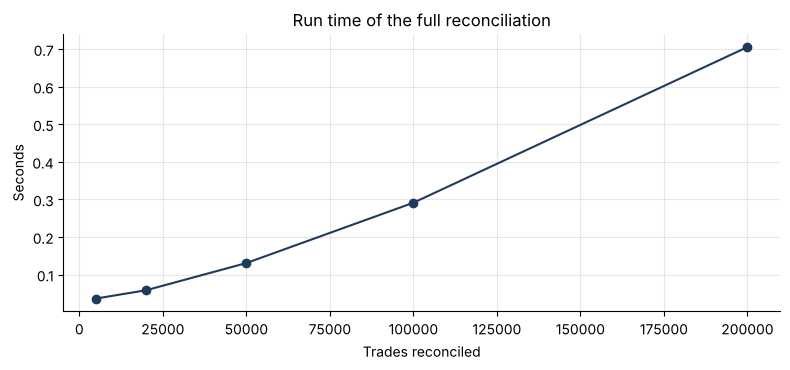

,Seconds
5000,0.04
20000,0.06
50000,0.13
100000,0.29
200000,0.71


In [7]:
sizes = [5_000, 20_000, 50_000, 100_000, 200_000]
times = []
for n in sizes:
    i_book = generate_trades(n, seed=10)
    e_book, _ = counterparty_view(i_book, seed=11)
    t0 = time.perf_counter(); reconcile(i_book, e_book); times.append(time.perf_counter() - t0)
plt.figure(figsize=(8, 3.8))
plt.plot(sizes, times, "o-", color=NAVY)
plt.xlabel("Trades reconciled"); plt.ylabel("Seconds"); plt.title("Run time of the full reconciliation")
plt.tight_layout(); plt.savefig("images/scaling.png", dpi=150); plt.show()
pd.Series(times, index=sizes).round(2).to_frame("Seconds")

## Conclusions
- The engine finds every injected break, raises no false alarm on valuation noise, and
  re-pairs trades that arrive without a UTI.
- 200,000 trades are reconciled in well under a second with vectorised pandas joins: a manual
  or spreadsheet process doing the same checks takes hours.
- **Next steps:** read real trade-repository files (EMIR Refit XML / ISO 20022), break
  ageing and ownership, and an automatic email to each counterparty with its breaks.